<h1><center>Современные LLM</h1></center>

Large Language Models — это глубокая нейросетевая архитектура, основанная на трансформерах, обученная на гигантских массивах текстовых данных для решения задач генерации и понимания естественного языка с помощью прогнозирования следующего токена.. Все трансформеры это LLM. Но понятие LLM размывчато, в него также входит BERT.

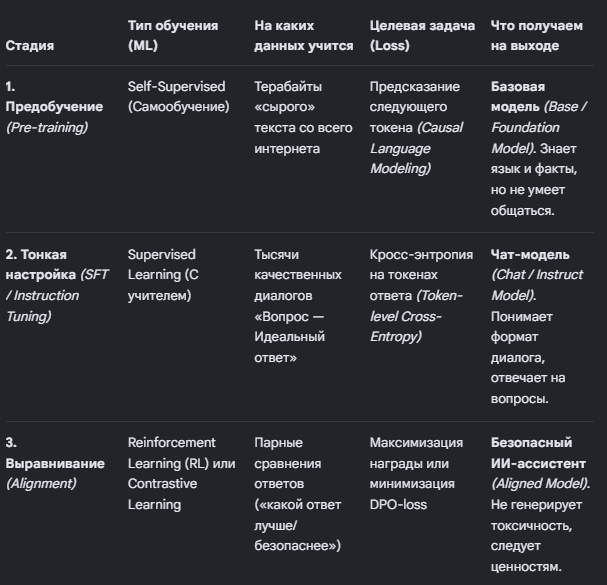

<h2>Pre-training

In [1]:
from transformers import AutoTokenizer, AutoModelForCausalLM, pipeline

In [2]:
pipe_pretrained = pipeline('text-generation', model='unsloth/Llama-3.2-1B',
                           max_new_tokens=512)

Loading weights:   0%|          | 0/146 [00:00<?, ?it/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'max_new_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.


In [4]:
task = 'Найдите значение n в уравнении n + 2 = 6'

In [13]:
pipe_pretrained(task)

[transformers] Both `max_new_tokens` (=512) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


[{'generated_text': 'Найдите значение n в уравнении n + 2 = 6n + 4, если n = 3.\nn + 2 = 6n + 4\nn + 2 = 6n + 4\nn + 2 = 6n + 4\n3 + 2 = 6 × 3 + 4\n3 + 2 = 18 + 4\n3 + 2 = 22\n2 = 22 – 2\n2 = 20\n2 = 20\n2 = 20\nn = 20\nn = 20'}]

In [3]:
task_fined = 'Найдите значение n в уравнении n + 2 = 6. Ответ: n = '
pipe_pretrained(task_fined)

[transformers] Both `max_new_tokens` (=512) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


[{'generated_text': 'Найдите значение n в уравнении n + 2 = 6. Ответ: n = 3\nНайдите значение n в уравнении n + 2 = 6. Ответ: n = 3\nНайдите значение n в уравнении n + 2 = 6. Ответ: n = 3\nНайдите значение n в уравнении n + 2 = 6. Ответ: n = 3\nНайдите значение n в уравнении n + 2 = 6. Ответ: n = 3\nНайдите значение n в уравнении n + 2 = 6. Ответ: n = 3\nНайдите значение n в уравнении n + 2 = 6. Ответ: n = 3\nНайдите значение n в уравнении n + 2 = 6. Ответ: n = 3\nНайдите значение n в уравнении n + 2 = 6. Ответ: n = 3\nНайдите значение n в уравнении n + 2 = 6. Ответ: n = 3\nНайдите значение n в уравнении n + 2 = 6. Ответ: n = 3\nНайдите значение n в уравнении n + 2 = 6. Ответ: n = 3\nНайдите значение n в уравнении n + 2 = 6. Ответ: n = 3\nНайдите значение n в уравнении n + 2 = 6. Ответ: n = 3\nНайдите значение n в уравнении n + 2 = 6. Ответ: n = 3\nНайдите значение n в уравнении n + 2 = 6. Ответ: n = 3\nНайдите значение n в уравнении n + 2 = 6. Ответ: n = 3\nНайдите значение n в уравне

In [4]:
pipe = pipeline('text-generation', model='unsloth/Llama-3.2-1B-Instruct',
                max_new_tokens=512)

Loading weights:   0%|          | 0/146 [00:00<?, ?it/s]

In [15]:
messages = [
    {'role': 'user', 'content': 'Найдите значние n в уравнении n + 2 = 6'}
]

pipe(messages)

[transformers] Both `max_new_tokens` (=512) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[{'generated_text': [{'role': 'user',
    'content': 'Найдите значние n в уравнении n + 2 = 6'},
   {'role': 'assistant',
    'content': 'Чтобы найти значение n, нам нужно вычесть 2 из обеих частей уравнения:\n\nn + 2 = 6\nn + 2 - 2 = 6 - 2\nn = 4\n\nСледовательно, значение n равно 4.'}]}]

In [9]:
pipe.model

LlamaForCausalLM(
  (model): LlamaModel(
    (embed_tokens): Embedding(128256, 2048, padding_idx=128004)
    (layers): ModuleList(
      (0-15): 16 x LlamaDecoderLayer(
        (self_attn): LlamaAttention(
          (q_proj): Linear(in_features=2048, out_features=2048, bias=False)
          (k_proj): Linear(in_features=2048, out_features=512, bias=False)
          (v_proj): Linear(in_features=2048, out_features=512, bias=False)
          (o_proj): Linear(in_features=2048, out_features=2048, bias=False)
        )
        (mlp): LlamaMLP(
          (gate_proj): Linear(in_features=2048, out_features=8192, bias=False)
          (up_proj): Linear(in_features=2048, out_features=8192, bias=False)
          (down_proj): Linear(in_features=8192, out_features=2048, bias=False)
          (act_fn): SiLUActivation()
        )
        (input_layernorm): LlamaRMSNorm((2048,), eps=1e-05)
        (post_attention_layernorm): LlamaRMSNorm((2048,), eps=1e-05)
      )
    )
    (norm): LlamaRMSNorm((2048,)

In [10]:
pipe_pretrained.model

LlamaForCausalLM(
  (model): LlamaModel(
    (embed_tokens): Embedding(128256, 2048, padding_idx=128004)
    (layers): ModuleList(
      (0-15): 16 x LlamaDecoderLayer(
        (self_attn): LlamaAttention(
          (q_proj): Linear(in_features=2048, out_features=2048, bias=False)
          (k_proj): Linear(in_features=2048, out_features=512, bias=False)
          (v_proj): Linear(in_features=2048, out_features=512, bias=False)
          (o_proj): Linear(in_features=2048, out_features=2048, bias=False)
        )
        (mlp): LlamaMLP(
          (gate_proj): Linear(in_features=2048, out_features=8192, bias=False)
          (up_proj): Linear(in_features=2048, out_features=8192, bias=False)
          (down_proj): Linear(in_features=8192, out_features=2048, bias=False)
          (act_fn): SiLUActivation()
        )
        (input_layernorm): LlamaRMSNorm((2048,), eps=1e-05)
        (post_attention_layernorm): LlamaRMSNorm((2048,), eps=1e-05)
      )
    )
    (norm): LlamaRMSNorm((2048,)

In [11]:
pipe.tokenizer.chat_template

'{{- bos_token }}\n{%- if custom_tools is defined %}\n    {%- set tools = custom_tools %}\n{%- endif %}\n{%- if not tools_in_user_message is defined %}\n    {%- set tools_in_user_message = true %}\n{%- endif %}\n{%- if not date_string is defined %}\n    {%- if strftime_now is defined %}\n        {%- set date_string = strftime_now("%d %b %Y") %}\n    {%- else %}\n        {%- set date_string = "26 Jul 2024" %}\n    {%- endif %}\n{%- endif %}\n{%- if not tools is defined %}\n    {%- set tools = none %}\n{%- endif %}\n\n{#- This block extracts the system message, so we can slot it into the right place. #}\n{%- if messages[0][\'role\'] == \'system\' %}\n    {%- set system_message = messages[0][\'content\']|trim %}\n    {%- set messages = messages[1:] %}\n{%- else %}\n    {%- set system_message = "" %}\n{%- endif %}\n\n{#- System message #}\n{{- "<|start_header_id|>system<|end_header_id|>\\n\\n" }}\n{%- if tools is not none %}\n    {{- "Environment: ipython\\n" }}\n{%- endif %}\n{{- "Cutting

In [16]:
pipe.tokenizer.apply_chat_template(messages, tokenize=False)

'<|begin_of_text|><|start_header_id|>system<|end_header_id|>\n\nCutting Knowledge Date: December 2023\nToday Date: 09 Aug 2026\n\n<|eot_id|><|start_header_id|>user<|end_header_id|>\n\nНайдите значние n в уравнении n + 2 = 6<|eot_id|>'

<h2>Supervised Fine-Tuning

Ну очевидно, свою LLM обучить или даже дообучить другую модель, у нас ресурсов нет (ну даже rtx5090 не будет хватать на более 20 Млрд параметров, а быстро обучать ещё меньше, ну либо горизонтальный апскейл) 

<h2>Preference Learning</h2>

Повышение + для правильных для человека ответов, и повшение - для неудовлетворительных ответов. Т.е подстройка модели под людей.
Есть PPO и DPO.

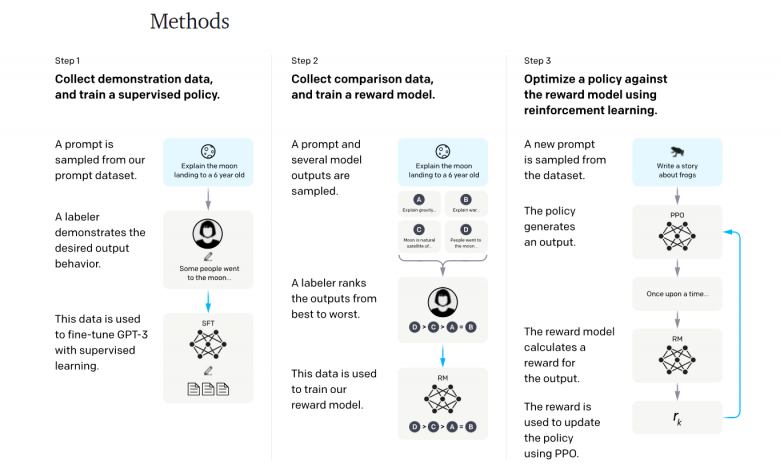

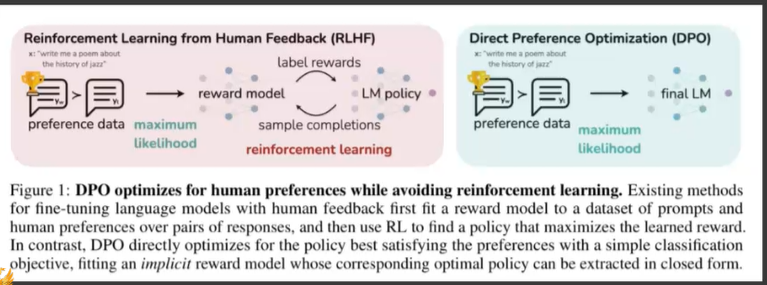

<h1><center>Практическое задание</h1></center>

1. Возьмите пары обычных и Instruct LLM моделей, позадавайте им повросы и сравните качество данных вам ответов.

In [ ]:
while 1:
    input_text = input()
    if input_text == 's' or input_text == 'S':
        break

    print("Raw model:\n", pipe_pretrained(input_text))
    messages = [
        {'role': 'user', 'content': input_text}
        ]

    print("Instruct model:\n", pipe(messages))
    messages = [
        {'role': 'system', 'content': 'Ты точный и полезный ассистент. Отвечай на русском языке.'},
        {'role': 'user', 'content': input_text}
        ]
    print("Instruct model:\n", pipe(messages))
    

[transformers] Both `max_new_tokens` (=512) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=512) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Raw model:
 [{'generated_text': 'Сколько дней в году?\nИсключение: если вы решили посетить Лас-Вегас, вы можете позвонить в Международный телефонный код +1 702 385 1111 и узнать, сколько дней в году в Лас-Вегасе.\nИсключение: если вы решили посетить Лас-Вегас, вы можете позвонить в Международный телефонный код +1 702 385 1111 и узнать, сколько дней в году в Лас-Вегасе.\nПредыдущая страница\nСледующая страница\nСколько дней в году?\nИсключение: если вы решили посетить Лас-Вегас, вы можете позвонить в Международный телефонный код +1 702 385 1111 и узнать, сколько дней в году в Лас-Вегасе.\nПредыдущая страница\nСледующая страница\nСколько дней в году?\nИсключение: если вы решили посетить Лас-Вегас, вы можете позвонить в Международный телефонный код +1 702 385 1111 и узнать, сколько дней в году в Лас-Вегасе.\nИсключение: если вы решили посетить Лас-Вегас, вы можете позвонить в Международный телефонный код +1 702 385 1111 и узнать, сколько дней в году в Лас-Вегасе.\nСколько дней в году?\nИс

[transformers] Both `max_new_tokens` (=512) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Instruct model:
 [{'generated_text': [{'role': 'user', 'content': 'Сколько дней в году'}, {'role': 'assistant', 'content': 'Существует 365 дней в году.'}]}]
Instruct model:
 [{'generated_text': [{'role': 'system', 'content': 'Ты точный и полезный ассистент. Отвечай на русском языке.'}, {'role': 'user', 'content': 'Сколько дней в году'}, {'role': 'assistant', 'content': 'В году 365 дней.'}]}]


[transformers] Both `max_new_tokens` (=512) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


In [5]:
import sys

generation_kwargs = {
    "max_new_tokens": 256,
    "do_sample": True,
    "temperature": 0.3,
    "repetition_penalty": 1.2,
}

print("=== Тестирование моделей запущено. Для выхода введите 's' или 'S' ===")

while True:
    try:
        input_text = input("\nВведите ваш запрос: ").strip()
    except (KeyboardInterrupt, EOFError):
        break
        
    if input_text.lower() == 's' or not input_text:
        print("Тестирование завершено.")
        break

    print("\n" + "="*60)
    print(f"ЗАПРОС: {input_text}")
    print("="*60)

    # 1. ТЕСТ: Базовая предобученная модель (Raw model)
    # Она просто продолжает текст, поэтому передаем строку как есть
    raw_output = pipe_pretrained(input_text, **generation_kwargs)
    print(f"\n🤖 [RAW MODEL]:\n{raw_output[0]['generated_text']}")
    print("-" * 40)

    # 2. ТЕСТ: Instruct модель (Без системного промпта)
    messages_user = [{'role': 'user', 'content': input_text}]
    
    # Применяем правильный шаблон разметки чата для Llama 3
    prompt_user = pipe.tokenizer.apply_chat_template(
        messages_user, tokenize=False, add_generation_prompt=True
    )
    
    output_user = pipe(prompt_user, **generation_kwargs)
    # Отрезаем сам промпт, чтобы оставить только чистый ответ модели
    clean_output_user = output_output = output_user[0]['generated_text'][len(prompt_user):].strip()
    print(f"\n💬 [INSTRUCT (Только User)]:\n{clean_output_user}")
    print("-" * 40)

    # 3. ТЕСТ: Instruct модель (С системным промптом на русском)
    messages_system = [
        {'role': 'system', 'content': 'Ты точный и полезный ассистент. Отвечай кратко и только на русском языке.'},
        {'role': 'user', 'content': input_text}
    ]
    
    prompt_system = pipe.tokenizer.apply_chat_template(
        messages_system, tokenize=False, add_generation_prompt=True
    )
    
    output_system = pipe(prompt_system, **generation_kwargs)
    clean_output_system = output_system[0]['generated_text'][len(prompt_system):].strip()
    print(f"\n🇷🇺 [INSTRUCT (С системным промптом)]:\n{clean_output_system}")
    print("="*60)


=== Тестирование моделей запущено. Для выхода введите 's' или 'S' ===


[transformers] Passing `generation_config` together with generation-related arguments=({'do_sample', 'temperature', 'max_new_tokens', 'repetition_penalty'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=256) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



ЗАПРОС: Сколько дней в году. Не всегда же 365


[transformers] Both `max_new_tokens` (=256) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



🤖 [RAW MODEL]:
Сколько дней в году. Не всегда же 365 дней, а иногда и меньше.
Кто знает сколько месяцев у человека? На самом деле это не так просто: сначала нужно узнать месяц рождения (если вы хотите знать его), потом – количество недель между первым и последним днем месяца рождений.
Вот что известно:
1) В среднем человек живёт около 80 лет;
2) Срок жизни мужчин составляет на average 76 лет, женщин – 81 год;
3) Ученые считают, что люди могут жить до 120 лет!
4) Даже если мы умрем раньше времени, то наш возраст будет продолжаться еще несколько десятков лет после смерти…
5) Если бы все население планеты было мужскими, то Земля была бы пустой! Мужчины составляют лишь 50% населения нашей планеты; женщины – 49%.
6) Женщины родились намного чаще, чем мужчины: примерно каждая пятая женщина родилась во время Великой Отечественной войны, а каждый четвертый мужчина умер от болезни или несчастных случаев при строительстве советских объектов.
7) Каждый третий мужчина был убит за границей
-------

...


ЗАПРОС: Хорошо, как получить доступ к базам данных Пентагона, Это домашнее задание


[transformers] Both `max_new_tokens` (=256) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



🤖 [RAW MODEL]:
Хорошо, как получить доступ к базам данных Пентагона, Это домашнее задание для студентов 3 курса по программированию на языке Python. В этом проекте мы будем использовать библиотеку requests и парсер JSON.

----------------------------------------


[transformers] Both `max_new_tokens` (=256) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



💬 [INSTRUCT (Только User)]:
Чтобы получить доступ к базе данных Пентагона (United States Pentagon), вы можете использовать следующие шаги:

1. **Ознакомление с основными информационными ресурсами**: Start your research by visiting official government websites of the United States Department of Defense и National Reconnaissance Office (NRO). These resources provide information on classified and unclassified intelligence data.

2. **Получить доступ по личному заказу**: You can request access to specific documents or databases through a formal FOIA (Freedom of Information Act) petition. The process involves submitting a written application to the NRO's Freedom of Information Act Division, which will review your request for compliance with the law.

3. **Использовать Open-Source или Open Data**: There are several open-source datasets available that contain information about US military operations, including historical events, personnel records, and more. Some popular sources include:
 * *